# Predicting Students’ Final Grades With Different Grade Availability
ITS836: Data Science in Big Data Analytics

## Introduction
Educational prediction can help educators identify students who may need support. Earlier period grades are closely associated with final achievement, but models without those grades face a harder prediction task. This project compares mathematics and Portuguese separately using the UCI Student Performance dataset (Cortez, 2008; Cortez & Silva, 2008).

**RQ1:** How does final-grade prediction change when no period grades, G1, or G1 and G2 are supplied?
**RQ2:** Which non-grade predictors does the no-grade model rely on?
**RQ3:** How well does a classifier identify students with G3 < 10 under each feature set?

**H1:** Adding G1 substantially improves prediction. **H2:** Non-grade predictors improve on simple constant baselines.

These are retrospective feature-availability experiments. Questionnaire collection times are not established, so “no grades” does not establish first-day-of-school prediction. Absences are excluded from every primary feature set because stage-specific attendance is unavailable. Zero final grades are retained: the data does not establish which zero grades indicate dropout.

## README / reproduction
Use Python 3.13.1 and the versions in `requirements.txt`. From this folder run `python -m pip install -r requirements.txt`, then `jupyter notebook Student_grade_convention.ipynb`. Restart the kernel and run all cells in order. Both semicolon-separated CSV files must be in this folder. Execution writes tables, figures, and environment metadata to `review_outputs/`. Seeds are fixed, but matching software versions is also necessary. The original submitted notebook and paper are backed up in that folder.


In [1]:
from pathlib import Path
import json, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance
OUT = Path('review_outputs'); OUT.mkdir(exist_ok=True)
SEED = 42
raw = {"Math": pd.read_csv('student-mat.csv', sep=';'),
       "Portuguese": pd.read_csv('student-por.csv', sep=';')}
environment = {'python': platform.python_version(), **{p: importlib.metadata.version(p) for p in ['numpy','pandas','scikit-learn','matplotlib','seaborn','nbformat','notebook']}}
(OUT / 'environment.json').write_text(json.dumps(environment, indent=2))
print(environment)


{'python': '3.13.1', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'matplotlib': '3.10.0', 'seaborn': '0.13.2', 'nbformat': '5.10.4', 'notebook': '7.3.2'}


## Data and preprocessing
The files contain 395 mathematics and 649 Portuguese course records, each with 33 columns. Some students appear in both courses; the models are separate, and the two course results are not independent replications. G1, G2, and G3 use a 0–20 scale; G3 < 10 defines at risk. Missingness and summaries are checked below. No outcome-based deletion is applied in the primary analysis.

A fixed 80/20 split is stratified by the at-risk label. The same students are used at every stage and for both prediction tasks within each course. One-hot encoding is fitted inside each training fold with unknown categories ignored. Numeric ordinal variables retain their recorded coding; linear regression therefore assumes equal increments in these codes.


    Course  Students  Mean G3  SD G3  Pass rate  Zero grades
      Math       395   10.415  4.581      0.671           38
Portuguese       649   11.906  3.231      0.846           15


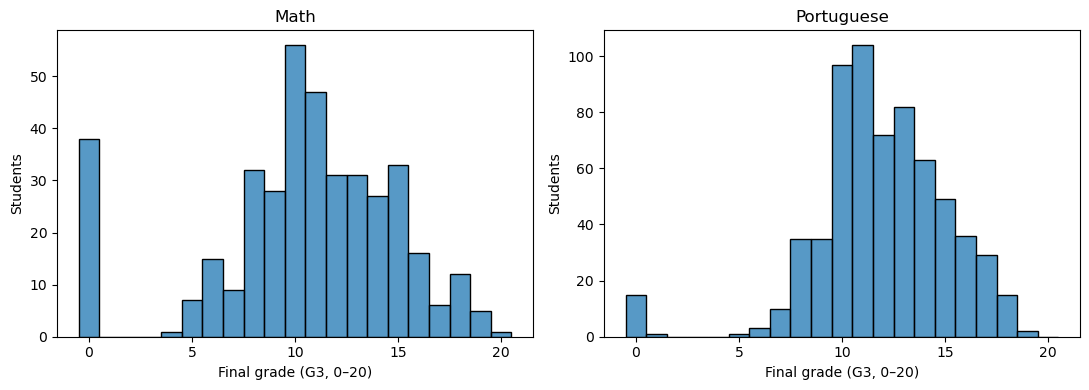

In [2]:
summary = []
for course, df in raw.items():
    assert df.shape[1] == 33 and df.isna().sum().sum() == 0
    summary.append({'Course': course, 'Students': len(df), 'Mean G3': df.G3.mean(),
                    'SD G3': df.G3.std(), 'Pass rate': (df.G3 >= 10).mean(),
                    'Zero grades': int((df.G3 == 0).sum())})
summary_df = pd.DataFrame(summary)
summary_df.to_csv(OUT / 'summary.csv', index=False)
print(summary_df.round(3).to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (course, df) in zip(axes, raw.items()):
    sns.histplot(df.G3, bins=np.arange(-.5, 21.5, 1), ax=ax)
    ax.set(title=course, xlabel='Final grade (G3, 0–20)', ylabel='Students')
fig.tight_layout(); fig.savefig(OUT / 'figure1.png', dpi=180); plt.show()


In [3]:
background = [c for c in raw['Math'].columns if c not in ['G1', 'G2', 'G3', 'absences']]
stages = {'No grades': background, '+ G1': background + ['G1'], '+ G1 + G2': background + ['G1', 'G2']}
splits = {}
for course, df in raw.items():
    train, test = train_test_split(df, test_size=.2, random_state=SEED, stratify=(df.G3 < 10))
    splits[course] = (train.copy(), test.copy())
    print(course, 'train:', len(train), 'test:', len(test), 'test at risk:', int((test.G3 < 10).sum()))

def pipeline(frame, estimator):
    categorical = frame.select_dtypes(exclude='number').columns.tolist()
    numeric = frame.select_dtypes(include='number').columns.tolist()
    preprocess = ColumnTransformer([
        ('categories', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical),
        ('numbers', 'passthrough', numeric)])
    return Pipeline([('preprocess', preprocess), ('model', clone(estimator))])


Math train: 316 test: 79 test at risk: 26
Portuguese train: 519 test: 130 test at risk: 20


## Regression methods
Linear regression, random forest (300 trees), and gradient boosting (100 trees, learning rate .1, maximum depth 3) are compared. Five-fold shuffled cross-validation on the training set selects a model independently for each course and stage using MAE. Only that selected model is then evaluated on the held-out test set. R² and MAE are reported; selection does not use test scores. Both training-mean and training-median baselines are included, because the median minimizes constant-prediction absolute error. Metrics retain full precision until display.


    Course     Stage Selected model  CV MAE    R2   MAE
      Math No grades  Random forest   3.348 0.109 3.228
      Math      + G1  Random forest   2.021 0.608 2.038
      Math + G1 + G2  Random forest   1.262 0.813 1.273
Portuguese No grades  Random forest   1.960 0.220 2.248
Portuguese      + G1  Random forest   1.224 0.652 1.423
Portuguese + G1 + G2  Random forest   0.803 0.806 0.938
    Course Baseline   MAE
      Math     mean 3.418
      Math   median 3.367
Portuguese     mean 2.600
Portuguese   median 2.592


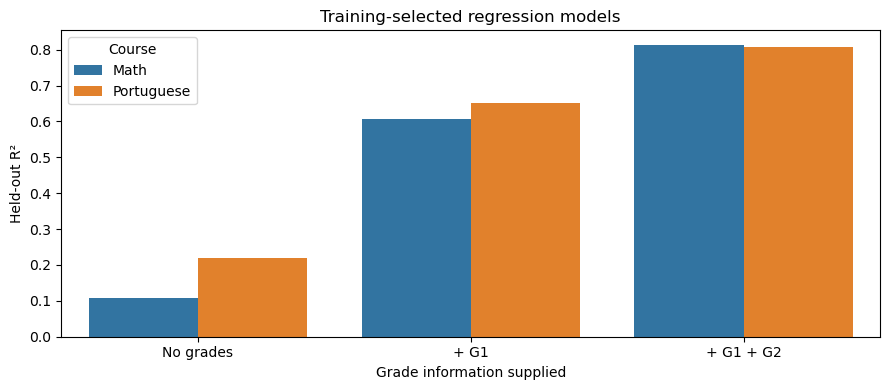

In [4]:
regressors = {'Linear regression': LinearRegression(),
              'Random forest': RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1),
              'Gradient boosting': GradientBoostingRegressor(n_estimators=100, learning_rate=.1, max_depth=3, random_state=SEED)}
cv_rows, reg_rows, baseline_rows = [], [], []
fitted = {}
for course, (train, test) in splits.items():
    for strategy in ['mean', 'median']:
        dummy = DummyRegressor(strategy=strategy).fit(train[background], train.G3)
        pred = dummy.predict(test[background])
        baseline_rows.append({'Course': course, 'Baseline': strategy, 'MAE': mean_absolute_error(test.G3, pred)})
    for stage, cols in stages.items():
        scores = {}
        for name, estimator in regressors.items():
            model = pipeline(train[cols], estimator)
            fold_mae = -cross_val_score(model, train[cols], train.G3,
                cv=KFold(5, shuffle=True, random_state=SEED), scoring='neg_mean_absolute_error')
            scores[name] = fold_mae.mean()
            cv_rows.append({'Course': course, 'Stage': stage, 'Model': name,
                            'CV MAE': fold_mae.mean(), 'CV fold SD': fold_mae.std(ddof=1)})
        best = min(scores, key=scores.get)
        model = pipeline(train[cols], regressors[best]).fit(train[cols], train.G3)
        pred = model.predict(test[cols]); fitted[(course, stage)] = model
        reg_rows.append({'Course': course, 'Stage': stage, 'Selected model': best,
                         'CV MAE': scores[best], 'R2': r2_score(test.G3, pred),
                         'MAE': mean_absolute_error(test.G3, pred)})
reg_df = pd.DataFrame(reg_rows); cv_df = pd.DataFrame(cv_rows); baseline_df = pd.DataFrame(baseline_rows)
for name, frame in [('regression',reg_df),('cross_validation',cv_df),('baselines',baseline_df)]:
    frame.to_csv(OUT / (name + '.csv'), index=False)
print(reg_df.round(3).to_string(index=False)); print(baseline_df.round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=reg_df, x='Stage', y='R2', hue='Course', ax=ax)
ax.set(ylabel='Held-out R²', xlabel='Grade information supplied', title='Training-selected regression models')
fig.tight_layout(); fig.savefig(OUT / 'figure2.png', dpi=180); plt.show()


## Model reliance on non-grade predictors
A prespecified random forest is used for comparable interpretation in both courses, regardless of which regressor wins cross-validation. Permutation importance is evaluated on held-out data using 20 shuffles and MAE. It shuffles an original variable through the full pipeline, keeping its encoded categories together. The plotted standard deviation describes shuffle variability, not a population confidence interval. Importance establishes neither direction nor causation, and correlated variables can share predictive information.


     Variable  Importance  Shuffle SD
14   failures       0.533       0.120
15  schoolsup       0.142       0.073
11   guardian       0.099       0.047
27       Walc       0.059       0.027
24   freetime       0.046       0.021
43   failures       0.229       0.086
49     higher       0.094       0.050
36       Fedu       0.080       0.030
44  schoolsup       0.042       0.025
31        age       0.040       0.021


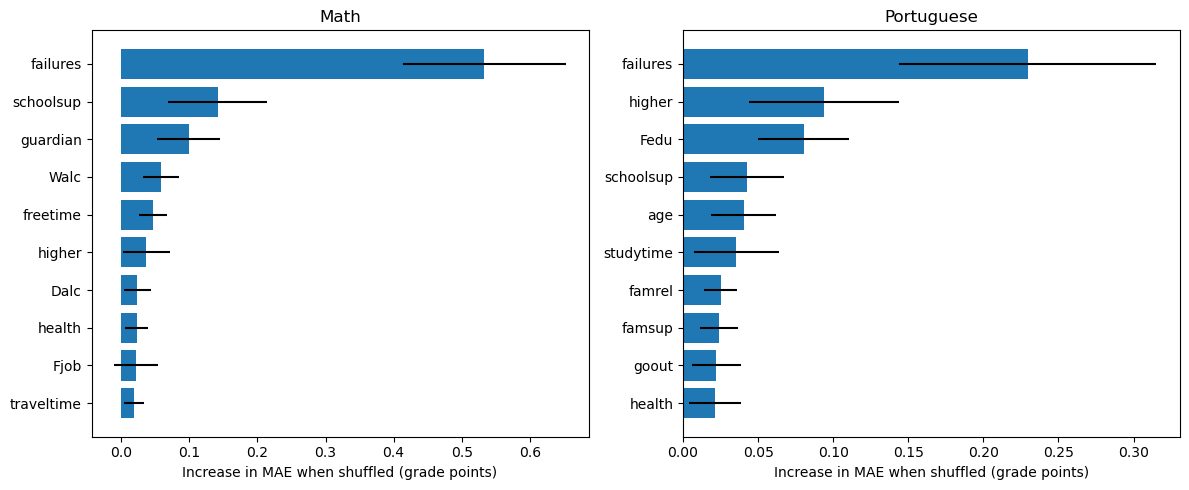

In [5]:
importance_rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (course, (train, test)) in zip(axes, splits.items()):
    model = pipeline(train[background], regressors['Random forest']).fit(train[background], train.G3)
    perm = permutation_importance(model, test[background], test.G3, n_repeats=20,
                                  random_state=SEED, scoring='neg_mean_absolute_error')
    table = pd.DataFrame({'Course': course, 'Variable': background,
                          'Importance': perm.importances_mean, 'Shuffle SD': perm.importances_std})
    importance_rows.extend(table.to_dict('records'))
    top = table.nlargest(10, 'Importance').sort_values('Importance')
    ax.barh(top.Variable, top.Importance, xerr=top['Shuffle SD'])
    ax.set(title=course, xlabel='Increase in MAE when shuffled (grade points)')
importance_df = pd.DataFrame(importance_rows)
importance_df.to_csv(OUT / 'importance.csv', index=False)
fig.tight_layout(); fig.savefig(OUT / 'figure3.png', dpi=180); plt.show()
print(importance_df.groupby('Course', group_keys=False).apply(lambda x: x.nlargest(5, 'Importance'), include_groups=False).round(3))


## Identifying at-risk students
A prespecified random forest classifier uses 300 trees, balanced class weights, and the default decision threshold. It is not selected using test outcomes. Training-only stratified five-fold cross-validation estimates recall before final test evaluation. Test accuracy, precision, recall, F1, and confusion counts are reported, together with an always-pass baseline. Wilson 95% intervals quantify uncertainty in held-out recall; these intervals do not capture all model-training uncertainty. Threshold tuning and intervention utility are outside this experiment.


    Course     Stage  CV recall  Accuracy  Precision  Recall    F1  Recall lower  Recall upper  TN  FP  FN  TP  Always-pass accuracy
      Math No grades      0.233     0.722      0.700   0.269 0.389         0.137         0.461  50   3  19   7                 0.671
      Math      + G1      0.599     0.810      0.720   0.692 0.706         0.500         0.835  46   7   8  18                 0.671
      Math + G1 + G2      0.924     0.911      0.852   0.885 0.868         0.710         0.960  49   4   3  23                 0.671
Portuguese No grades      0.088     0.831      0.333   0.100 0.154         0.028         0.301 106   4  18   2                 0.846
Portuguese      + G1      0.250     0.869      0.667   0.300 0.414         0.145         0.519 107   3  14   6                 0.846
Portuguese + G1 + G2      0.638     0.915      0.737   0.700 0.718         0.481         0.855 105   5   6  14                 0.846


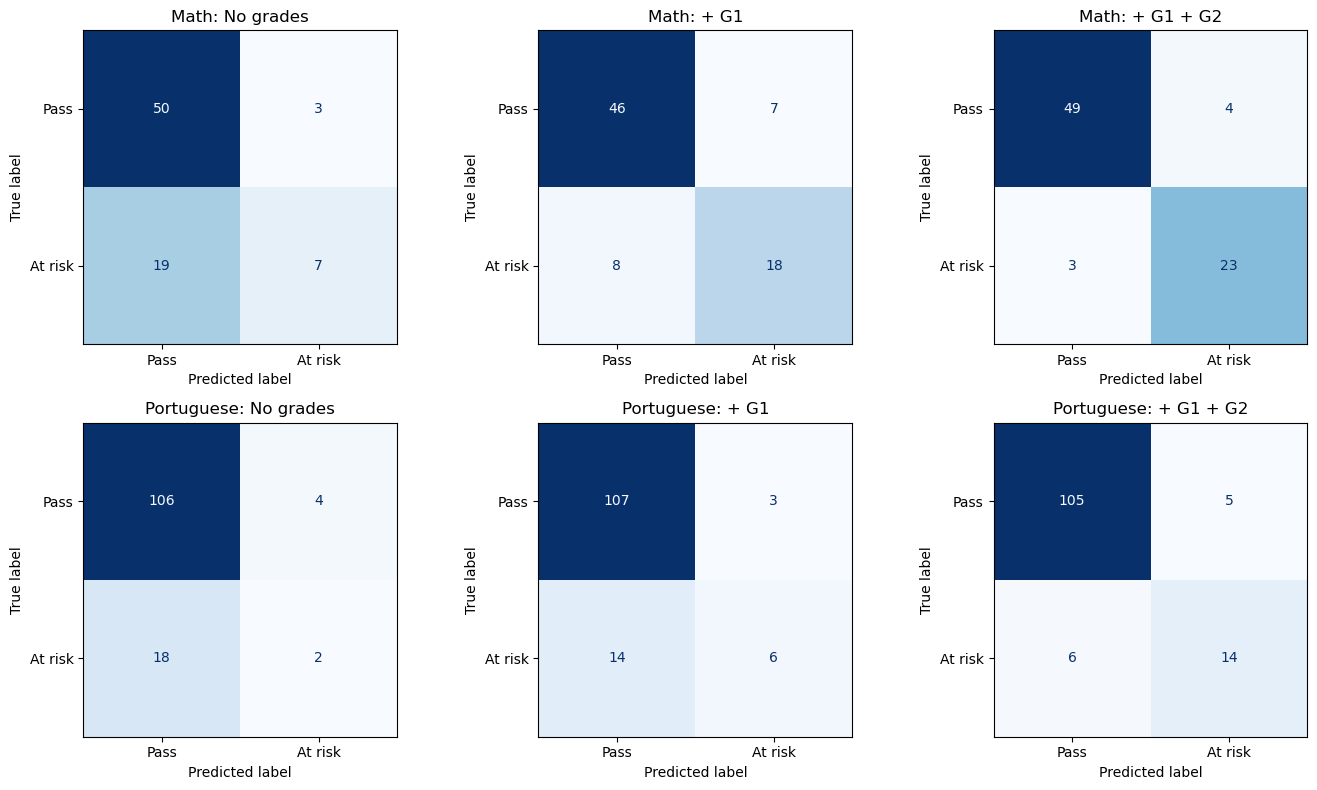

In [6]:
def wilson(successes, total):
    if total == 0: return (np.nan, np.nan)
    z = 1.959963984540054; p = successes / total; den = 1 + z*z/total
    center = (p + z*z/(2*total))/den
    half = z*np.sqrt(p*(1-p)/total + z*z/(4*total*total))/den
    return center-half, center+half
class_rows = []
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for row, (course, (train, test)) in enumerate(splits.items()):
    y_train, y_test = (train.G3 < 10).astype(int), (test.G3 < 10).astype(int)
    for col, (stage, cols) in enumerate(stages.items()):
        model = pipeline(train[cols], RandomForestClassifier(n_estimators=300, random_state=SEED,
                                                           class_weight='balanced', n_jobs=-1))
        cv_recall = cross_val_score(model, train[cols], y_train,
            cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring='recall')
        model.fit(train[cols], y_train); pred = model.predict(test[cols])
        cm = confusion_matrix(y_test, pred, labels=[0,1]); tn, fp, fn, tp = cm.ravel()
        lo, hi = wilson(tp, tp+fn)
        class_rows.append({'Course':course, 'Stage':stage, 'CV recall':cv_recall.mean(),
            'Accuracy':accuracy_score(y_test,pred), 'Precision':precision_score(y_test,pred,zero_division=0),
            'Recall':recall_score(y_test,pred,zero_division=0), 'F1':f1_score(y_test,pred,zero_division=0),
            'Recall lower':lo, 'Recall upper':hi, 'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp),
            'Always-pass accuracy':(y_test==0).mean()})
        ConfusionMatrixDisplay(cm, display_labels=['Pass','At risk']).plot(ax=axes[row,col], colorbar=False, cmap='Blues')
        axes[row,col].set_title(f'{course}: {stage}')
class_df = pd.DataFrame(class_rows); class_df.to_csv(OUT / 'classification.csv',index=False)
fig.tight_layout(); fig.savefig(OUT / 'figure4.png',dpi=180); plt.show()
print(class_df.round(3).to_string(index=False))


## Sensitivity to excluding zero grades
The primary analysis retains all zero grades. This secondary comparison excludes G3 = 0, matching the original population restriction. The selected primary regression model type is reused without test-driven reselection. Each restricted dataset gets its own stratified split; the test populations differ, so differences cannot be attributed solely to removing zeros. This comparison does not identify dropout or establish a causal effect of filtering.


## Findings, discussion, and conclusion

**RQ1 / H1.** Adding G1 reduced held-out MAE in both courses, supporting H1 descriptively.

Math: MAE across no grades, G1, and G1 plus G2 was 3.23, 2.04, 1.27 grade points; R² was 0.109, 0.608, 0.813.

Portuguese: MAE across no grades, G1, and G1 plus G2 was 2.25, 1.42, 0.94 grade points; R² was 0.220, 0.652, 0.806.

**H2.** No-grade MAE was lower than both constant baselines in both courses, supporting H2 on this split. The mathematics advantage was small; these differences are not a formal significance test.

**RQ2.** The largest no-grade importance values were:

Math: failures (0.533 MAE points), schoolsup (0.142 MAE points), guardian (0.099 MAE points). These measure model reliance, not effect direction or causation.

Portuguese: failures (0.229 MAE points), higher (0.094 MAE points), Fedu (0.080 MAE points). These measure model reliance, not effect direction or causation.

**RQ3.** At-risk recall increased with grade information, but differed substantially by course:

Math: 26.9%, 69.2%, 88.5% recall across the three feature sets. Read these values with precision, false alarms, and the reported recall intervals.

Portuguese: 10.0%, 30.0%, 70.0% recall across the three feature sets. Read these values with precision, false alarms, and the reported recall intervals.

This pattern addresses the same broad with/without-grades question as Cortez and Silva (2008). Numerical comparisons with earlier studies require matching outcome populations, metrics, and validation designs. The evidence supports the predictive contribution of period grades; it does not establish first-day availability or intervention effectiveness. The value of the project is a reproducible comparison that exposes both predictive gains and the limitations of early-warning claims.

In [7]:
sensitivity_rows = []
for course, original in raw.items():
    df = original.loc[original.G3 > 0].copy()
    train, test = train_test_split(df, test_size=.2, random_state=SEED, stratify=(df.G3<10))
    for stage, cols in stages.items():
        name = reg_df.loc[(reg_df.Course==course)&(reg_df.Stage==stage),'Selected model'].iloc[0]
        model = pipeline(train[cols], regressors[name]).fit(train[cols],train.G3)
        pred = model.predict(test[cols])
        clf = pipeline(train[cols],RandomForestClassifier(n_estimators=300, random_state=SEED,
                        class_weight='balanced',n_jobs=-1)).fit(train[cols],(train.G3<10).astype(int))
        cp = clf.predict(test[cols])
        sensitivity_rows.append({'Course':course,'Stage':stage,'Students':len(df),
            'Model':name,'MAE':mean_absolute_error(test.G3,pred),'R2':r2_score(test.G3,pred),
            'Recall':recall_score((test.G3<10).astype(int),cp,zero_division=0)})
sensitivity_df=pd.DataFrame(sensitivity_rows)
sensitivity_df.to_csv(OUT/'sensitivity.csv',index=False)
print(sensitivity_df.round(3).to_string(index=False))


    Course     Stage  Students         Model   MAE    R2  Recall
      Math No grades       357 Random forest 2.356 0.126   0.000
      Math      + G1       357 Random forest 1.267 0.774   0.263
      Math + G1 + G2       357 Random forest 0.648 0.930   0.789
Portuguese No grades       634 Random forest 1.947 0.319   0.000
Portuguese      + G1       634 Random forest 1.146 0.715   0.235
Portuguese + G1 + G2       634 Random forest 0.783 0.812   0.471


## Discussion and conclusion
The generated tables distinguish training cross-validation from held-out performance. Compare the no-grade model with both constant baselines for H2, and compare its MAE with the G1 stage for H1. Recall must be interpreted alongside precision, false alarms, and uncertainty rather than accuracy alone. Non-grade permutation importance answers RQ2 as a statement of model reliance, not a causal explanation.

Limitations include small samples from two Portuguese schools, overlapping students across courses, historical and self-reported data, uncertain predictor collection times, a single held-out split, ordinal coding assumptions, and unverified meanings of zero outcomes. Neither predictive associations nor balanced class weights establish that an intervention will help. Prospective validation using dated inputs, broader datasets, subgroup evaluation, and training-only threshold selection should precede operational use. See the accompanying revised paper for the numerical interpretation and comparison with prior work.

## References
Cortez, P. (2008). *Student performance* [Data set]. UCI Machine Learning Repository. https://doi.org/10.24432/C5TG7T

Cortez, P., & Silva, A. M. G. (2008). Using data mining to predict secondary school student performance. In *Proceedings of the 5th Future Business Technology Conference* (pp. 5–12). EUROSIS.
